[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Alokothro/movie-recommender-svd/blob/main/notebooks/02_baselines.ipynb)

# Project 2: A Movie Recommendation System
## Milestone 2 — Honest Testing and Baselines to Beat
*MATH 344L: Applied Linear Algebra Lab*

Before building anything fancy, we need a fair way to tell whether a recommender actually works. The
plan is to hide some ratings, build every model using only the ratings that are left, and then score
the models on the hidden ones. We also build a few simple average-based recommenders. Their scores
are the **baselines** that the SVD model has to beat in the next milestone.

**The rule:** a hidden test rating can never be used to build a model.

ratings → training ratings → model → predictions on hidden ratings

We measure error with RMSE. A lower RMSE means more accurate predictions.

## Part A: Load the MovieLens ratings

In [1]:
import os, urllib.request, zipfile
import numpy as np
import pandas as pd

if not os.path.exists("ml-100k"):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip")
    zipfile.ZipFile("ml-100k.zip").extractall()

ratings = pd.read_csv(
    "ml-100k/u.data", sep="\t",
    names=["user", "item", "rating", "time"])

print(ratings.head())
print("Number of ratings:", len(ratings))

   user  item  rating       time
0   196   242       3  881250949
1   186   302       3  891717742
2    22   377       1  878887116
3   244    51       2  880606923
4   166   346       1  886397596
Number of ratings: 100000


This cell loads the data. The first lines bring in the tools for downloading and unzipping files,
plus NumPy and pandas. The `if` check only downloads the zip file when the `ml-100k` folder isn't
already there, so running the notebook again doesn't download everything again. Then `pd.read_csv`
reads the ratings file into a table. The columns are separated by tabs, so we use `sep="\t"` and give
the four columns names.

Each row is one rating: a user, a movie, how many stars, and a timestamp. There are 100,000 rows, one
for every known rating. This is called *long form*. Later we turn the training ratings into a
user-by-movie matrix.

## Part B: Make an honest train/test split

In [2]:
def split_ratings(ratings, test_frac=0.10, seed=0):
    """Hide ratings without removing a user's or movie's last training rating."""
    rng = np.random.default_rng(seed)
    is_test = np.zeros(len(ratings), dtype=bool)

    user_left = ratings.groupby("user").size().to_dict()
    item_left = ratings.groupby("item").size().to_dict()

    for pos in rng.permutation(len(ratings)):
        row = ratings.iloc[pos]
        user, item = row["user"], row["item"]

        if (rng.random() < test_frac
                and user_left[user] > 1
                and item_left[item] > 1):
            is_test[pos] = True
            user_left[user] -= 1
            item_left[item] -= 1

    return ratings.iloc[~is_test].copy(), ratings.iloc[is_test].copy()

train, test = split_ratings(ratings)
print("train:", len(train), "test:", len(test))
print("test fraction:", round(len(test) / len(ratings), 3))

train: 90032 test: 9968
test fraction: 0.1


This function splits the ratings into a training set and a test set. It goes through the ratings in a
random order (`rng.permutation`), and each one gets about a 10% chance of being hidden
(`rng.random() < test_frac`). `is_test` is a True/False array that keeps track of which ratings got
hidden.

The catch is that it never hides a user's or a movie's last remaining rating. `user_left` and
`item_left` count how many training ratings each user and movie still has, and a rating only gets
hidden if both counts are above 1. That way every user and every movie still has at least one rating
to learn from.

At the end, the `~` in front of `is_test` flips True and False, so `ratings.iloc[~is_test]` is
everything that stayed in training and `ratings.iloc[is_test]` is the hidden test set.

We got 90,032 training ratings and 9,968 test ratings, so the test set is right around 10%. Because
`seed=0` is fixed, the split comes out exactly the same every time, so every model gets tested on the
same hidden ratings and the comparison is fair.

**Data leakage:** if a hidden test rating sneaks into any step of building a model (an average, a
fill-in value, or an SVD), the score looks better than it really is. Exercise 2 shows what that
looks like.

## Part C: Build the training matrix

In [3]:
N_USERS, N_ITEMS = 943, 1682

def to_matrix(df):
    """Return a user-by-movie matrix; missing ratings are np.nan."""
    R = np.full((N_USERS, N_ITEMS), np.nan)
    R[df["user"].to_numpy() - 1,
      df["item"].to_numpy() - 1] = df["rating"].to_numpy()
    return R

R = to_matrix(train)
known = ~np.isnan(R)

print("Matrix shape:", R.shape)
print("Known training ratings:", known.sum())

Matrix shape: (943, 1682)
Known training ratings: 90032


This builds the training matrix `R`, with one row per user and one column per movie. `np.full`
starts with a 943 × 1682 matrix that's completely filled with `np.nan`, and then each training rating
gets dropped into its spot. The user and movie IDs start at 1, but Python positions start at 0, so we
subtract 1 from every ID.

`np.nan` means "we don't know this rating," not zero stars. `known` is True wherever there's a
training rating. It counts 90,032 known ratings, exactly the size of the training set, so every
training rating made it into the matrix.

In [4]:
truth = test["rating"].to_numpy()
u = test["user"].to_numpy() - 1
i = test["item"].to_numpy() - 1

These are the answers we'll check our guesses against. `truth` holds the real star rating for each
hidden test rating, and `u` and `i` are that rating's row and column in the matrix (again minus 1,
since Python starts at 0). So `truth[j]` is the rating user `u[j]` actually gave movie `i[j]`, and
every model has to guess it.

## Part D: Score predictions with RMSE

In [5]:
def rmse(pred, truth):
    """Root mean squared error, measured in stars."""
    return np.sqrt(np.mean((pred - truth)**2))

RMSE stands for *root mean squared error*. For every hidden rating, it takes the error (prediction
minus the real rating) and squares it so negative and positive errors don't cancel out. Then it
averages all the squared errors and takes the square root to get back to stars:

$$\text{RMSE} = \sqrt{\frac{1}{N}\sum_{j=1}^{N} (\text{prediction}_j - \text{truth}_j)^2}$$

An RMSE of about 1 means the guesses are usually about one star off. Lower is better.

## Part E: Build simple baselines

In [6]:
mu = np.nanmean(R)
user_mean = np.nanmean(R, axis=1)

n_item = known.sum(axis=0)
item_mean = np.full(N_ITEMS, mu)
has_rating = n_item > 0
item_mean[has_rating] = (
    np.nansum(R, axis=0)[has_rating] / n_item[has_rating])

print("Overall average:", round(mu, 3))

Overall average: 3.53


These are the averages the simple models use, all computed from the training matrix only.
`np.nanmean` takes an average while skipping the `nan`s. With no `axis`, `mu` is the average of every
training rating, about 3.53 stars. `axis=1` averages across each row, so `user_mean` has one average
for each user.

For movies, `known.sum(axis=0)` counts how many training ratings each movie column has, and
`item_mean` divides each column's total by that count. `item_mean` starts out as `mu` for every
movie, so a movie with no training ratings would just get the overall average. (Our split keeps at
least one training rating for every movie, so that doesn't actually happen here.)

In [7]:
scores = {}
scores["always 3"] = rmse(np.full(len(test), 3.0), truth)
scores["overall average"] = rmse(np.full(len(test), mu), truth)
scores["user average"] = rmse(user_mean[u], truth)
scores["movie average"] = rmse(item_mean[i], truth)

for name, score in scores.items():
    print(f"{name:16s} {score:.4f}")

always 3         1.2516
overall average  1.1349
user average     1.0426
movie average    1.0284


This scores four simple recommenders on the hidden ratings:

- **always 3:** guess 3 stars for everything
- **overall average:** guess `mu` (about 3.53) for everything
- **user average:** guess that user's average rating
- **movie average:** guess that movie's average rating

`np.full(len(test), 3.0)` makes one 3-star guess for every test rating, and `user_mean[u]` and
`item_mean[i]` look up the right average for each hidden rating.

Movie average does the best of these four (1.0284), even a little better than user average (1.0426).
That makes sense: movies are really different from each other in how good they are, so knowing
*which movie* it is tells you a lot about the rating.

## Part F: Combine user and movie effects
Some people rate everything high, and some movies almost everyone likes. The bias baseline uses both:

$$\text{prediction} = \mu + b_{\text{user}} + b_{\text{item}}$$

In [8]:
def bias_baseline(R):
    """Overall mean plus one user effect and one movie effect."""
    known = ~np.isnan(R)
    mu = np.nanmean(R)

    b_user = np.nanmean(R - mu, axis=1)
    residual = R - mu - b_user[:, None]

    n_item = known.sum(axis=0)
    b_item = np.zeros(R.shape[1])
    has_rating = n_item > 0
    b_item[has_rating] = (
        np.nansum(residual, axis=0)[has_rating] / n_item[has_rating])

    return mu, b_user, b_item

`b_user` is how far each user's ratings are from the overall average, on average. A generous rater
gets a positive `b_user` and a harsh rater gets a negative one. `b_user[:, None]` turns the list of
user effects into a column, so NumPy subtracts each user's effect from every rating in that user's
row.

What's left over is `residual`, the part of each rating that the overall average and the user effect
don't explain. `b_item` is the average leftover for each movie, which is the movie effect. A movie
with no training ratings would get an effect of 0.

In [9]:
mu, b_user, b_item = bias_baseline(R)
pred = np.clip(mu + b_user[u] + b_item[i], 1, 5)

scores["user + movie effects"] = rmse(pred, truth)
print(pd.Series(scores, name="test RMSE").round(4).sort_values())

user + movie effects    0.9545
movie average           1.0284
user average            1.0426
overall average         1.1349
always 3                1.2516
Name: test RMSE, dtype: float64


This makes a prediction for every hidden rating by adding the overall average, that user's effect,
and that movie's effect. `np.clip(..., 1, 5)` keeps the predictions between 1 and 5 stars, since
something like 5.4 stars isn't a real rating.

**User + movie effects gets an RMSE of 0.9545, the best of all five,** and it's the only one that
gets under one star of error. This is the score the SVD model has to beat in Milestone 3. It's still
just a simple one-pass model, not a finished recommender.

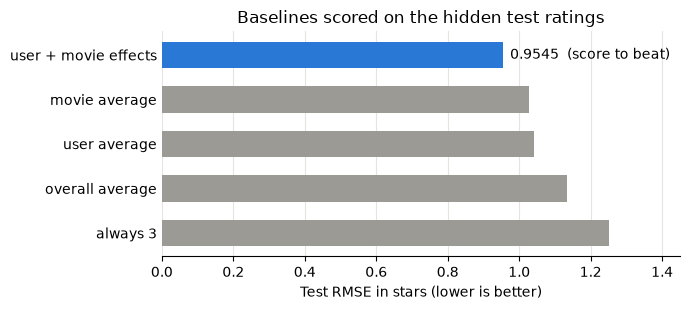

In [10]:
import matplotlib.pyplot as plt

results = pd.Series(scores).sort_values(ascending=False)
best = results.idxmin()
colors = ["#2a78d6" if name == best else "#9b9a94" for name in results.index]

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(results.index, results.values, color=colors, height=0.6)
ax.set_xlim(0, 1.45)
ax.set_xlabel("Test RMSE in stars (lower is better)")
ax.set_title("Baselines scored on the hidden test ratings")
ax.grid(axis="x", color="#e5e4df", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.text(results[best] + 0.02, len(results) - 1,
        f"{results[best]:.4f}  (score to beat)", va="center")
plt.tight_layout()
plt.show()

This chart shows the same five scores so they're easier to compare. Shorter bars are better, and the
blue bar is the best baseline, the one Milestone 3 has to beat. Going from "always 3" to "user +
movie effects" cuts the error from about 1.25 stars to about 0.95 stars.

**Key idea:** none of these models use the SVD yet. Their job is to give us a fair benchmark. A
fancier model is only worth it if it beats 0.9545 on the same hidden test ratings.

# Practice Exercises

### Exercise 1 — By hand, then by computer

$$\begin{bmatrix} 5 & 3 & ? \\ 4 & ? & 1 \\ ? & 2 & 2 \end{bmatrix}$$

**By hand:**

**μ (overall average):** the known ratings are 5, 3, 4, 1, 2, 2. They add up to 17, and there are 6
of them, so μ = 17/6 ≈ 2.833.

**b_user:** each user's average minus μ.
- User 1: (5 + 3)/2 = 4, so b = 4 − 2.833 ≈ **1.167**
- User 2: (4 + 1)/2 = 2.5, so b = 2.5 − 2.833 ≈ **−0.333**
- User 3: (2 + 2)/2 = 2, so b = 2 − 2.833 ≈ **−0.833**

**b_item:** first take each rating and subtract μ and the user's effect. Since μ + b_user is just that
user's average, this is the same as rating minus the user's average. Then average those leftovers
down each column.
- Movie 1: user 1 gives 5 − 4 = 1, user 2 gives 4 − 2.5 = 1.5, so b = (1 + 1.5)/2 = **1.25**
- Movie 2: user 1 gives 3 − 4 = −1, user 3 gives 2 − 2 = 0, so b = (−1 + 0)/2 = **−0.5**
- Movie 3: user 2 gives 1 − 2.5 = −1.5, user 3 gives 2 − 2 = 0, so b = (−1.5 + 0)/2 = **−0.75**

In [11]:
tiny = np.array([
    [5, 3, np.nan],
    [4, np.nan, 1],
    [np.nan, 2, 2],
])

mu_t, b_user_t, b_item_t = bias_baseline(tiny)
print("mu     =", round(mu_t, 3))
print("b_user =", np.round(b_user_t, 3))
print("b_item =", np.round(b_item_t, 3))

# Fill in the missing ratings with mu + b_user + b_item
filled = np.where(np.isnan(tiny), mu_t + b_user_t[:, None] + b_item_t, tiny)
print("\nFilled-in matrix:\n", np.round(filled, 2))

mu     = 2.833
b_user = [ 1.167 -0.333 -0.833]
b_item = [ 1.25 -0.5  -0.75]

Filled-in matrix:
 [[5.   3.   3.25]
 [4.   2.   1.  ]
 [3.25 2.   2.  ]]


The computer got the same numbers I got by hand: μ ≈ 2.833, b_user ≈ [1.167, −0.333, −0.833], and
b_item = [1.25, −0.5, −0.75].

Using those, the model fills in the three missing ratings as **3.25** (user 1, movie 3), **2.0** (user
2, movie 2), and **3.25** (user 3, movie 1). For example, user 1 rates high (+1.167) but movie 3 gets
rated low (−0.75), so the guess lands in the middle: 2.833 + 1.167 − 0.75 = 3.25.

### Exercise 2 — See what cheating looks like

In [12]:
R_all = to_matrix(ratings)   # uses ALL the ratings, including the hidden test ones
cheat_user_mean = np.nanmean(R_all, axis=1)

print("Honest user average RMSE:  ", round(scores["user average"], 4))
print("Cheating user average RMSE:", round(rmse(cheat_user_mean[u], truth), 4))

Honest user average RMSE:   1.0426
Cheating user average RMSE: 1.0322


Yes, the cheating version scores lower: **1.0322**, compared with **1.0426** for the honest one.

But that score is misleading. When we built the matrix from *all* the ratings, the hidden test
ratings got mixed into the user averages, so the model already partly knew the answers it was being
tested on. That's data leakage. In real life a recommender has to guess ratings people haven't given
yet, so only the honest score tells us how well it would actually do.

### Exercise 3 — Is it luck?

In [13]:
def all_scores(train, test):
    """Train all five baselines on train and return their RMSE on test."""
    R = to_matrix(train)
    known = ~np.isnan(R)
    truth = test["rating"].to_numpy()
    u = test["user"].to_numpy() - 1
    i = test["item"].to_numpy() - 1

    mu = np.nanmean(R)
    user_mean = np.nanmean(R, axis=1)
    n_item = known.sum(axis=0)
    item_mean = np.full(N_ITEMS, mu)
    has_rating = n_item > 0
    item_mean[has_rating] = np.nansum(R, axis=0)[has_rating] / n_item[has_rating]

    m, b_u, b_i = bias_baseline(R)
    return {
        "always 3": rmse(np.full(len(test), 3.0), truth),
        "overall average": rmse(np.full(len(test), mu), truth),
        "user average": rmse(user_mean[u], truth),
        "movie average": rmse(item_mean[i], truth),
        "user + movie effects": rmse(np.clip(m + b_u[u] + b_i[i], 1, 5), truth),
    }

To redo everything with a different split, I put all five baselines into one function. It does the
same steps as Parts C–F: build the training matrix, work out the averages and effects, and return the
five RMSE scores on the test set.

In [14]:
train1, test1 = split_ratings(ratings, seed=1)
print("seed 1 -> train:", len(train1), "test:", len(test1))

compare = pd.DataFrame({
    "seed 0": all_scores(train, test),
    "seed 1": all_scores(train1, test1),
})
compare["change"] = compare["seed 1"] - compare["seed 0"]
compare["rank (seed 0)"] = compare["seed 0"].rank().astype(int)
compare["rank (seed 1)"] = compare["seed 1"].rank().astype(int)
compare.sort_values("seed 0").round(4)

seed 1 -> train: 90174 test: 9826


,seed 0,seed 1,change,rank (seed 0),rank (seed 1)
user + movie effects,0.9545,0.9577,0.0032,1,1
movie average,1.0284,1.0159,-0.0125,2,2
user average,1.0426,1.0345,-0.0081,3,3
overall average,1.1349,1.1127,-0.0222,4,4
always 3,1.2516,1.2336,-0.0180,5,5


**Do the values change?** Yes, a little. Every score moves by somewhere between about 0.003 and 0.02
stars. For example, movie average goes from 1.0284 to 1.0159.

**Does the ranking change?** No. The order is the same both times: user + movie effects is the best,
then movie average, user average, overall average, and always 3 is the worst.

**What this tells me:** part of any score is just luck, depending on which ratings happened to land
in the test set. The gap between movie average and user average is only about 0.01 to 0.02 stars,
which is about as big as how much the scores move between seeds. So to compare two recommenders
fairly, we should test them on the exact same split, and if the difference is tiny, try a few
different seeds before saying one is really better.

# Summary
- To test a recommender honestly, we hid about 10% of the ratings and only used the other 90% to
  build each model.
- RMSE measures how many stars off the predictions are on the hidden ratings. Lower is better.
- From best to worst: user + movie effects **0.9545**, movie average 1.0284, user average 1.0426,
  overall average 1.1349, always 3 1.2516.
- Letting test ratings into the model (data leakage) makes the score look better than it really is.
- A different random split changes the scores a little but not the ranking, so tiny differences
  between models might just be luck.

**Score to beat in Milestone 3:** 0.9545 (user + movie effects).